# 04 · Correlation — pseudotime-windowed module Pearson
On the hub (basal convergence population), take the Gast-XOR-pSom genes and, in pseudotime windows, correlate each gene with the Gast and with the pSom module score, then correlate those two gene-loading vectors. Negative values mark windows where the modules pull apart.

In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
sc.settings.verbosity = 1

In [2]:
name = os.path.split(os.getcwd())[1]
cat  = os.path.split(os.path.split(os.getcwd())[0])[1]
pth  = os.path.join(*(['..']*4))
pth_data = os.path.join(pth, 'data')
pth_in   = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out  = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb   = os.path.join(pth_out, 'colorbars')

In [3]:
# load signatures data from h5ad file
adata = sc.read_h5ad(os.path.join(pth_in, 'signatures.h5ad')); adata

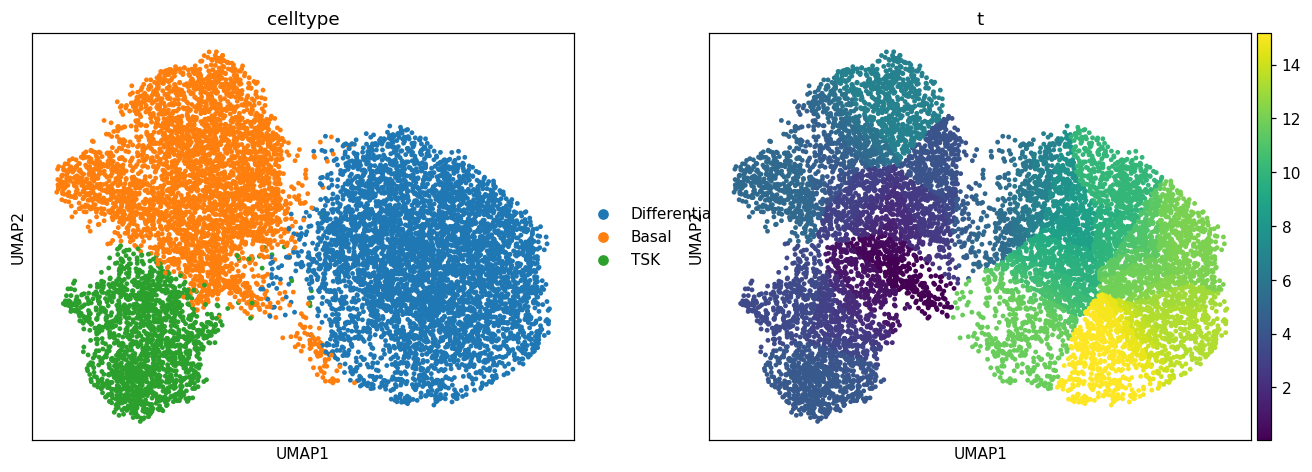

In [4]:
# visual inspection — loaded data
sc.pl.umap(adata, color = ['celltype', 't'], size = 40)

In [5]:
# select module genes — Gast XOR pSom (the modules that co-repress during development)
get_feat = lambda p: set(pd.read_csv(p).hsapiens)
gast = get_feat(os.path.join(pth_feat, 'GSE162534.csv'))
psom = get_feat(os.path.join(pth_feat, 'GSE229103.csv'))
g = pd.Series(list(gast ^ psom))
g = g.loc[g.isin(adata.var_names)]
print('XOR genes on manifold:', g.size)

XOR genes on manifold: 114


In [6]:
# select the hub — basal convergence population at the branch point / root
msk = (adata.obs.celltype == 'Basal')
adata_corr = adata[msk, g].copy(); adata_corr

In [7]:
# pseudotime windows (~100 cells each)
n_cells, t = 100, adata_corr.obs.t
n_bins = (t.size // n_cells)
t_bin = pd.cut(t, bins = n_bins)
adata_corr.obs['t_bin'] = t_bin
grp = adata_corr.obs.groupby('t_bin', observed = True)

In [8]:
# module mutual correlation, per window
r_dict = dict()
for b, sdf_bin in grp:
    if len(sdf_bin) < 5:
        r_dict[b] = np.nan; continue          # skip sparse pseudotime windows
    ab = adata_corr[sdf_bin.index].copy()
    X = pd.DataFrame(ab.X.toarray(), index = sdf_bin.index, columns = g)
    X = X.loc[:, (X.nunique(axis = 0) > 1)].copy()
    mod1 = sdf_bin.Gast.values[:, None]
    mod2 = sdf_bin.pSom.values[:, None]
    a_ = pearsonr(X, mod1, axis = 0).statistic
    b_ = pearsonr(X, mod2, axis = 0).statistic
    r_dict[b] = np.corrcoef(a_, b_)[0, 1]
A = adata_corr.obsp['connectivities']
R = t_bin.map(r_dict).astype(float)
R_sm = (A @ R) / A.sum(axis = 1).A1
adata_corr.obs['correlation'] = R_sm
print('windowed module r: mean %.2f  min %.2f  max %.2f' % (R.mean(), R.min(), R.max()))

windowed module r: mean -0.24  min -0.59  max 0.23


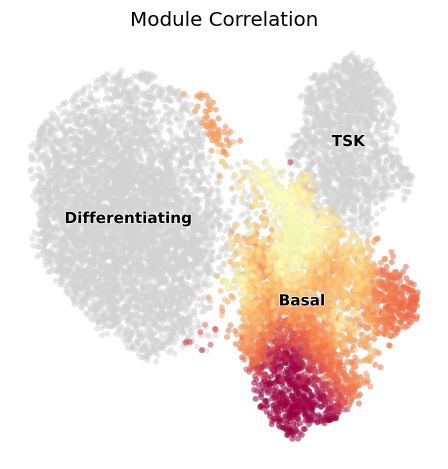

In [9]:
# save module correlation figure
vlim = .5
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, size = 60, alpha = .5, frameon = False, show = False, ax = ax)
sc.pl.umap(adata_corr, color = 'correlation', cmap = 'Spectral', vmin = -vlim, vmax = vlim,
           size = 60, alpha = .5, colorbar_loc = None, frameon = False, show = False, ax = ax)
sc.pl.umap(adata, color = 'celltype', size = 60, alpha = 0, legend_loc = 'on data',
           legend_fontoutline = 1, frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Module Correlation', size = 13)
fig.savefig(os.path.join(pth_out, 'correlation.pdf'), bbox_inches = 'tight')

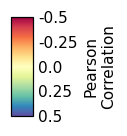

In [10]:
# save module correlation colorbar
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[1], cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('Pearson\nCorrelation')
cb.ax.invert_yaxis()
ticks = np.asarray([-.5, -.25, 0, .25, .5])
cb.set_ticks(ticks, labels = ticks)
cb.solids.set_alpha(1)
fig.savefig(os.path.join(pth_cb, 'R_colorbar.pdf'), bbox_inches = 'tight')